<a href="https://colab.research.google.com/github/SergeiVKalinin/Paper_Notebooks/blob/main/VAE_Walls/Main_01_Trained_VAE_Representations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Main 01 — Trained VAE representations (Figures 1, 3 and 6)

Each section is independent *after the common imports*. All models are trained here; no archived numerical panels, model weights, or encoded payloads are used.

- **Figure 1** requires **MNIST**. Colab downloads it through `torchvision` if necessary. Because this is a new training run, its pixels and layout are not expected to be identical to the original paper figure.
- **Figures 3 and 6** use the digits distributed with scikit-learn.
- Only individual PNG images are saved to `/content`; no composite manuscript figure is assembled.

The standard mode is a quick inspection. Set `FAST_MODE=False` before running to increase training budgets; the published paper's specific measurements require the corresponding documented seeds and training procedures.

In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# All user-visible output is PNG; nothing is cached or exported in other formats.
OUTPUT = Path('/content') if Path('/content').exists() else Path.cwd()
FAST_MODE = False       # False: use the longer, publication-scale calculations.
DPI = 180 if FAST_MODE else 300

def save_panel(fig, filename):
    fig.savefig(OUTPUT / filename, dpi=DPI, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved', OUTPUT / filename)

import torch
from torch import nn
from torch.nn import functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KernelDensity
from scipy.ndimage import rotate, zoom

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, 'Device:', DEVICE)

def seed_all(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

class VAE(nn.Module):
    def __init__(self, pixels, hidden=256):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(pixels, hidden), nn.ReLU(),
                                     nn.Linear(hidden, hidden), nn.ReLU())
        self.mu = nn.Linear(hidden, 2)
        self.logvar = nn.Linear(hidden, 2)
        self.decoder = nn.Sequential(nn.Linear(2, hidden), nn.ReLU(),
                                     nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, pixels))
    def encode(self, x):
        h = self.encoder(x)
        return self.mu(h), self.logvar(h).clamp(-12, 8)
    def forward(self, x):
        m, v = self.encode(x)
        z = m + torch.randn_like(m) * torch.exp(0.5*v)
        return self.decoder(z), m, v

def fit_vae(x, beta=1., epochs=10, batch_size=256, seed=17, hidden=256):
    seed_all(seed)
    data = torch.as_tensor(x, dtype=torch.float32)
    model = VAE(data.shape[1], hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    generator = torch.Generator().manual_seed(seed)
    loader = torch.utils.data.DataLoader(data, batch_size=batch_size, shuffle=True, generator=generator)
    model.train()
    for epoch in range(epochs):
        total = 0.
        for xbatch in loader:
            xbatch = xbatch.to(DEVICE)
            logits, mu, lv = model(xbatch)
            reconstruction = F.binary_cross_entropy_with_logits(logits, xbatch, reduction='sum') / len(xbatch)
            kl = (-0.5*(1 + lv - mu.square() - lv.exp()).sum()) / len(xbatch)
            loss = reconstruction + beta * kl
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(xbatch)
        if epoch == epochs - 1 or epoch % max(1, epochs//4)==0:
            print(f'Epoch {epoch+1}/{epochs}: loss {total/len(data):.3f}')
    model.eval()
    return model

@torch.no_grad()
def encode_all(model, x, batch=1024):
    return np.concatenate([model.encode(torch.as_tensor(x[i:i+batch],dtype=torch.float32,device=DEVICE))[0].cpu().numpy()
                           for i in range(0,len(x),batch)])

@torch.no_grad()
def decode_all(model, z, batch=2048):
    return np.concatenate([torch.sigmoid(model.decoder(torch.as_tensor(z[i:i+batch],dtype=torch.float32,device=DEVICE))).cpu().numpy()
                           for i in range(0,len(z),batch)])

PyTorch: 2.14.1+cpu Device: cpu


## Figure 1 — four MNIST diagnostics

We train a two-dimensional VAE, then separately measure encoded posterior means, decoded digit identities, an independent classifier's confidence, and the standard-normal-prior to encoded-mean-density ratio. The density estimate is **not** the complete aggregate posterior.

Epoch 1/25: loss 202.722
Epoch 7/25: loss 151.701
Epoch 13/25: loss 145.727
Epoch 19/25: loss 143.418
Epoch 25/25: loss 141.784


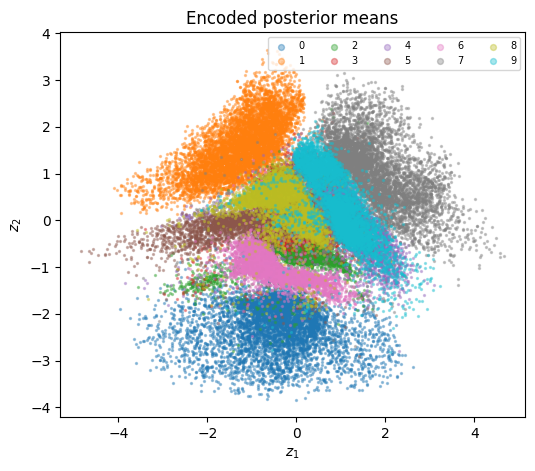

Saved /content/Fig01_a_encoded_means.png


In [7]:
from torchvision.datasets import MNIST
mnist = MNIST(root='/tmp/vae_mnist', train=True, download=True)
X_mnist = mnist.data.numpy().reshape(-1,784).astype('float32') / 255.
y_mnist = mnist.targets.numpy()
rng = np.random.default_rng(17)
select = rng.choice(len(X_mnist), size=min(len(X_mnist), 12000 if FAST_MODE else 60000), replace=False)
X_mnist, y_mnist = X_mnist[select], y_mnist[select]
mnist_vae = fit_vae(X_mnist, beta=1., epochs=3 if FAST_MODE else 25, hidden=256)
Z_mnist = encode_all(mnist_vae, X_mnist)
fig, ax = plt.subplots(figsize=(6,5))
for digit in range(10):
    pts=Z_mnist[y_mnist==digit]
    ax.scatter(pts[:,0],pts[:,1],s=2,alpha=.38,label=str(digit))
ax.set(xlabel='$z_1$',ylabel='$z_2$',title='Encoded posterior means')
ax.legend(ncol=5,fontsize=7,markerscale=3)
save_panel(fig,'Fig01_a_encoded_means.png')

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


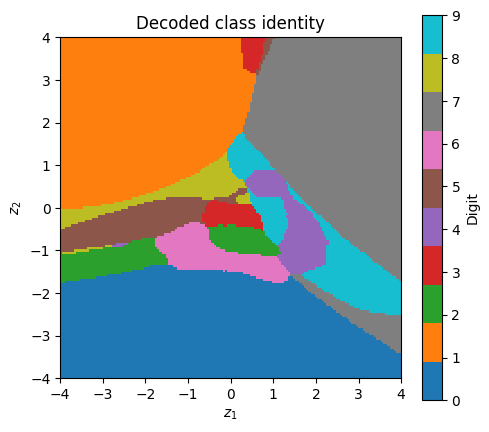

Saved /content/Fig01_b_decoded_domains.png


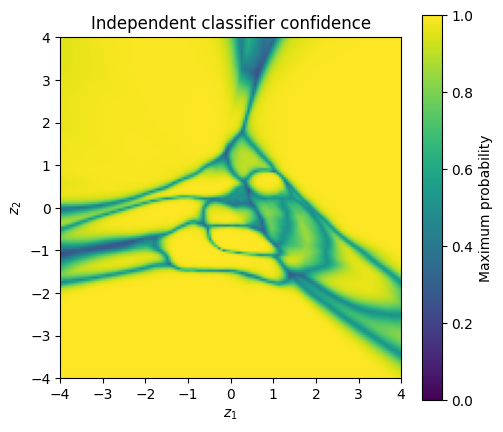

Saved /content/Fig01_c_classifier_confidence.png


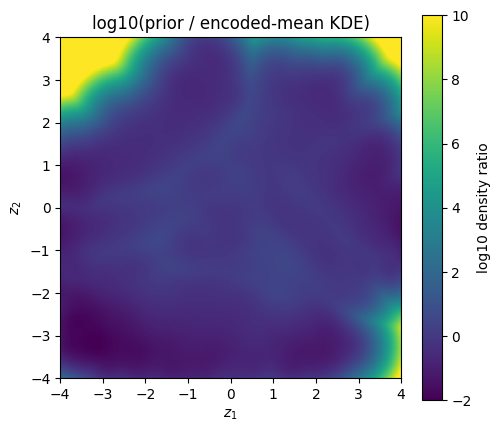

Saved /content/Fig01_d_prior_over_encoded_density.png


In [8]:
# Fit the classifier to observed images (not to decoded grid images).
classifier = LogisticRegression(max_iter=150, solver='lbfgs')
classifier.fit(X_mnist, y_mnist)
side = 65 if FAST_MODE else 151
u = np.linspace(-4., 4., side)
grid = np.column_stack([a.ravel() for a in np.meshgrid(u,u)])
decoded = decode_all(mnist_vae, grid)
prob = classifier.predict_proba(decoded)
labels = classifier.classes_[prob.argmax(1)].reshape(side,side)
confidence = prob.max(1).reshape(side,side)

fig,ax=plt.subplots(figsize=(5.5,5))
im=ax.imshow(labels,origin='lower',extent=(-4,4,-4,4),interpolation='nearest',cmap='tab10',vmin=0,vmax=9)
ax.set(xlabel='$z_1$',ylabel='$z_2$',title='Decoded class identity')
fig.colorbar(im,ax=ax,label='Digit')
save_panel(fig,'Fig01_b_decoded_domains.png')

fig,ax=plt.subplots(figsize=(5.5,5))
im=ax.imshow(confidence,origin='lower',extent=(-4,4,-4,4),vmin=0,vmax=1,cmap='viridis')
ax.set(xlabel='$z_1$',ylabel='$z_2$',title='Independent classifier confidence')
fig.colorbar(im,ax=ax,label='Maximum probability')
save_panel(fig,'Fig01_c_classifier_confidence.png')

# Standard Gaussian p(z) versus a KDE of encoded means q_mu(z).
kde = KernelDensity(kernel='gaussian', bandwidth=.20).fit(Z_mnist)
log_q = kde.score_samples(grid)
log_p = -.5 * np.sum(grid**2,axis=1)-np.log(2*np.pi)
ratio = ((log_p-log_q)/np.log(10)).reshape(side,side)
fig,ax=plt.subplots(figsize=(5.5,5))
im=ax.imshow(ratio,origin='lower',extent=(-4,4,-4,4),cmap='viridis',vmin=-2,vmax=10)
ax.set(xlabel='$z_1$',ylabel='$z_2$',title='log10(prior / encoded-mean KDE)')
fig.colorbar(im,ax=ax,label='log10 density ratio')
save_panel(fig,'Fig01_d_prior_over_encoded_density.png')

## Figure 3 — two-class digits benchmark

This is trained on the offline scikit-learn **8×8 digits**, not MNIST. The model is retrained for several KL weights. The width calculated below is an **encoded-mean Gaussian proxy**, not the full posterior wall width.

beta 2.0 completed
beta 4.0 completed
beta 8.0 completed
beta 16.0 completed


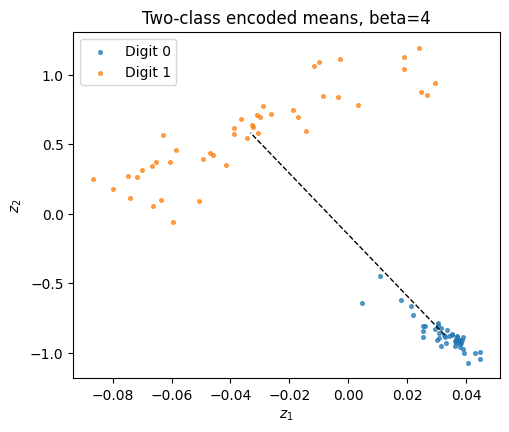

Saved /content/Fig03_a_latent_means.png


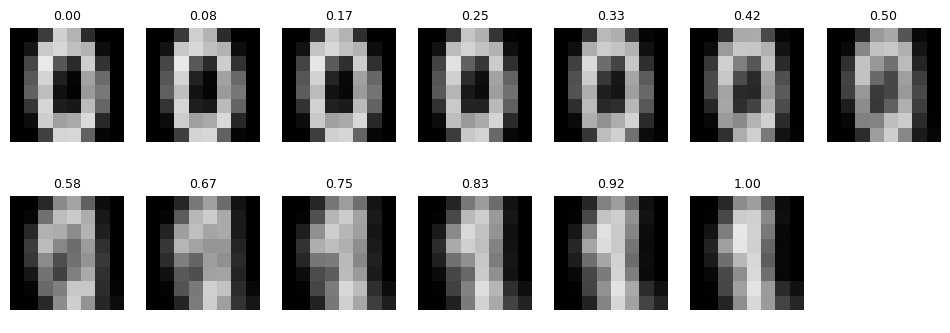

Saved /content/Fig03_b_decoded_transition.png


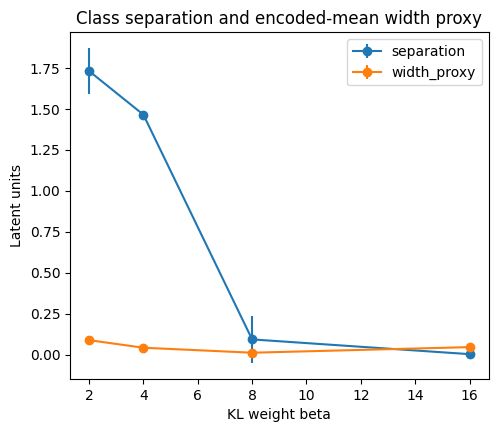

Saved /content/Fig03_c_separation_width.png


In [9]:
D = load_digits()
mask = np.isin(D.target,[0,1])
X01 = (D.data[mask]/16.).astype('float32')
y01 = D.target[mask]
x_train,x_test,y_train,y_test=train_test_split(X01,y01,test_size=.25,stratify=y01,random_state=137)
betas=[2.,4.,8.,16.]
seeds=[17] if FAST_MODE else [17,18,19]
steps=300 if FAST_MODE else 2200

# Use the same 128-unit hidden-layer width and BCE+beta*KL objective.
models={}; observations=[]
for beta in betas:
    for seed in seeds:
        seed_all(seed)
        model=VAE(64,hidden=128).to(DEVICE)
        opt=torch.optim.Adam(model.parameters(),lr=.001)
        g=torch.Generator().manual_seed(seed)
        loader=torch.utils.data.DataLoader(torch.tensor(x_train),batch_size=128,shuffle=True,generator=g)
        batchiter=iter(loader)
        for step in range(steps):
            try: xb=next(batchiter)
            except StopIteration:
                batchiter=iter(loader); xb=next(batchiter)
            xb=xb.to(DEVICE)
            logits,mu,lv=model(xb)
            loss=(F.binary_cross_entropy_with_logits(logits,xb,reduction='sum')+
                  beta*(-.5*(1+lv-mu.square()-lv.exp()).sum()))/len(xb)
            opt.zero_grad();loss.backward();opt.step()
        model.eval()
        z=encode_all(model,x_test)
        means=np.stack([z[y_test==k].mean(0) for k in [0,1]])
        cov=np.stack([np.cov(z[y_test==k].T)+np.eye(2)*1e-4 for k in [0,1]])
        sep=np.linalg.norm(means[1]-means[0])
        # One-dimensional log-odds slope along the class-center connecting direction.
        u=(means[1]-means[0])/max(sep,1e-9)
        pooled=(cov[0]+cov[1])/2
        width=float((u@pooled@u)/max(sep,1e-9))
        observations.append(dict(beta=beta,seed=seed,separation=sep,width_proxy=width))
        if seed==17: models[beta]=(model,z,means)
    print('beta',beta,'completed')

model,z,means=models[4.]
fig,ax=plt.subplots(figsize=(5.5,4.5))
for k in [0,1]: ax.scatter(z[y_test==k,0],z[y_test==k,1],s=7,label=f'Digit {k}',alpha=.7)
ax.plot(means[:,0],means[:,1],'k--',lw=1)
ax.set(xlabel='$z_1$',ylabel='$z_2$',title='Two-class encoded means, beta=4')
ax.legend()
save_panel(fig,'Fig03_a_latent_means.png')

start,end=means
path=np.linspace(start,end,13)
images=decode_all(model,path).reshape(-1,8,8)
fig,axs=plt.subplots(2,7,figsize=(12,4))
for i,ax in enumerate(axs.flat):
    ax.axis('off')
    if i<len(images):
        ax.imshow(images[i],cmap='gray',vmin=0,vmax=1)
        ax.set_title(f'{i/12:.2f}',fontsize=9)
save_panel(fig,'Fig03_b_decoded_transition.png')

fig,ax=plt.subplots(figsize=(5.4,4.5))
for metric in ['separation','width_proxy']:
    ys=np.array([[r[metric] for r in observations if r['beta']==b] for b in betas])
    ax.errorbar(betas,ys.mean(1),yerr=ys.std(1,ddof=1) if len(seeds)>1 else None,marker='o',label=metric)
ax.set(xlabel='KL weight beta',ylabel='Latent units',title='Class separation and encoded-mean width proxy')
ax.legend()
save_panel(fig,'Fig03_c_separation_width.png')

## Figure 6 — rotational digits

Four models are trained on random rotations of scikit-learn digits (individual digits 1, 0, and 8, and a mixture of 0, 1, 3, 8). We plot their encoded means and decoded latent grids separately. The sweeps reuse base images from the same original-image pool and are therefore **not identity-disjoint validation**.

Epoch 1/80: loss 436.966
Epoch 21/80: loss 169.519
Epoch 41/80: loss 167.089
Epoch 61/80: loss 165.634
Epoch 80/80: loss 164.236


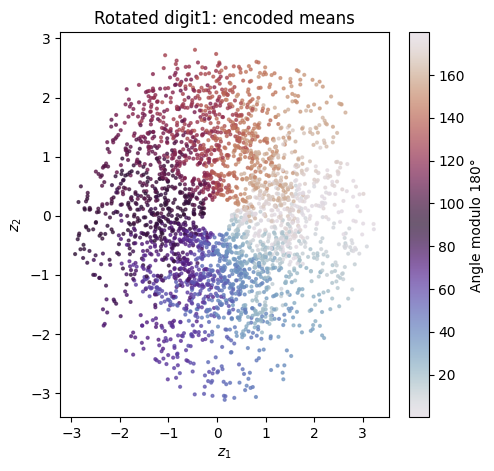

Saved /content/Fig06_digit1_encoded.png


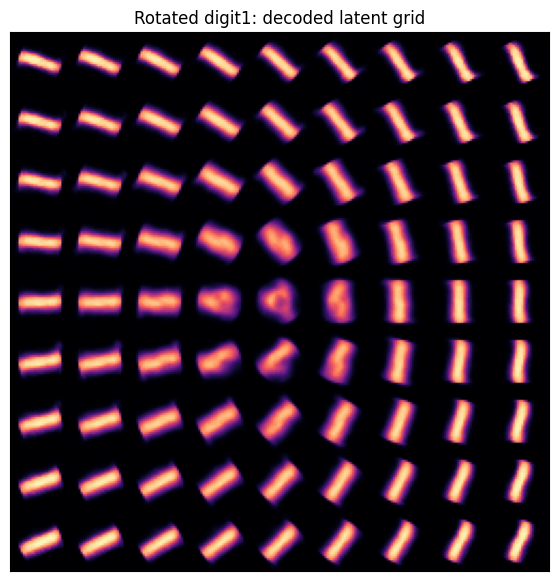

Saved /content/Fig06_digit1_decoded.png


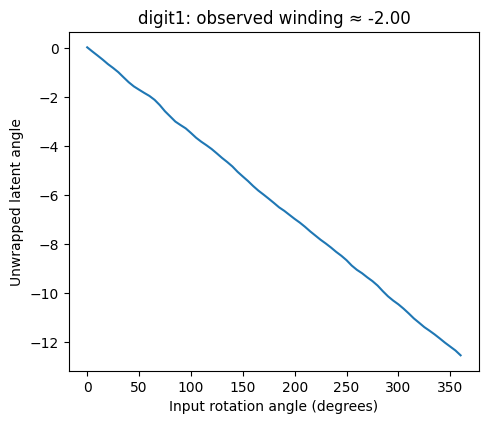

Saved /content/Fig06_digit1_winding.png
Epoch 1/80: loss 450.323
Epoch 21/80: loss 198.765
Epoch 41/80: loss 195.579
Epoch 61/80: loss 194.700
Epoch 80/80: loss 194.407


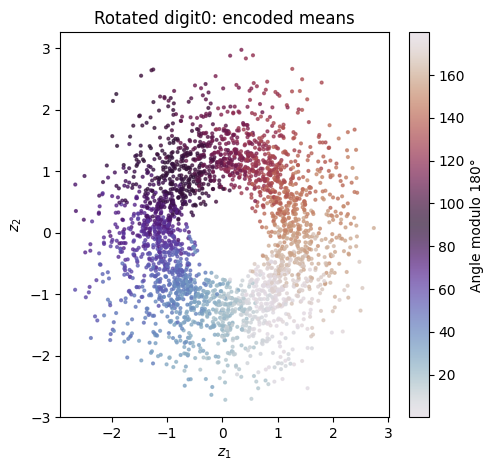

Saved /content/Fig06_digit0_encoded.png


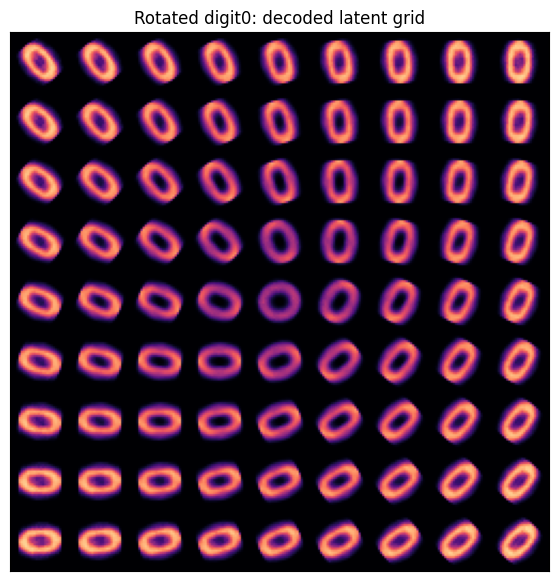

Saved /content/Fig06_digit0_decoded.png


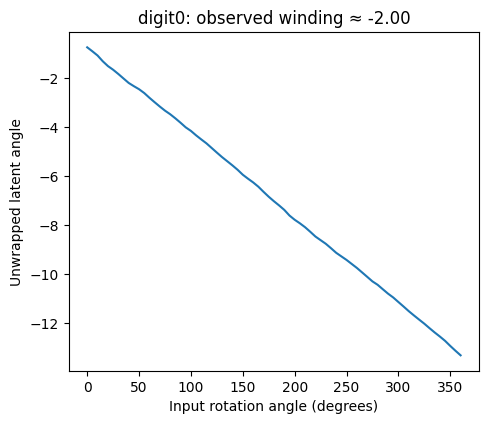

Saved /content/Fig06_digit0_winding.png
Epoch 1/80: loss 447.973
Epoch 21/80: loss 192.847
Epoch 41/80: loss 191.034
Epoch 61/80: loss 190.187
Epoch 80/80: loss 189.781


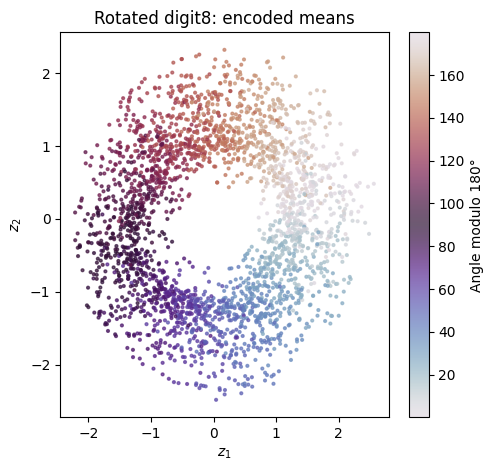

Saved /content/Fig06_digit8_encoded.png


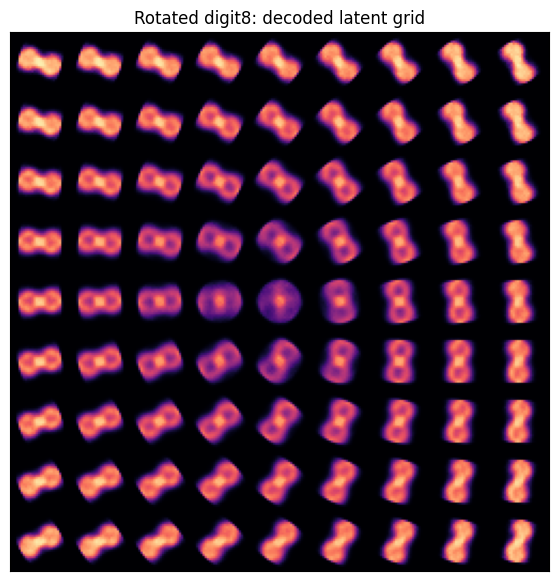

Saved /content/Fig06_digit8_decoded.png


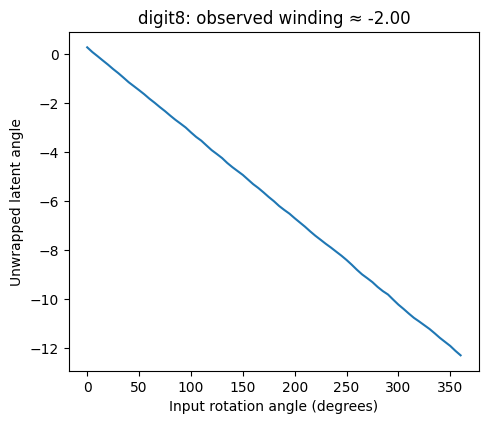

Saved /content/Fig06_digit8_winding.png
Epoch 1/80: loss 358.545
Epoch 21/80: loss 191.856
Epoch 41/80: loss 190.016
Epoch 61/80: loss 189.560
Epoch 80/80: loss 189.103


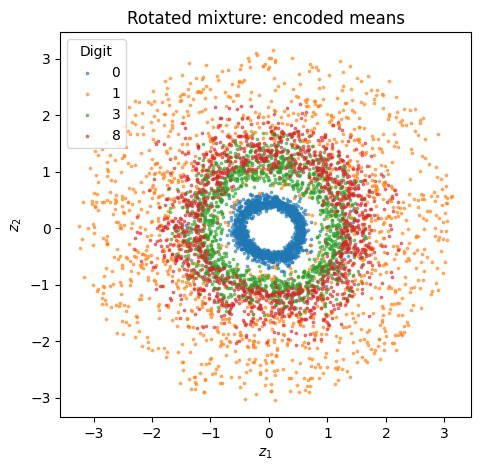

Saved /content/Fig06_mixture_encoded.png


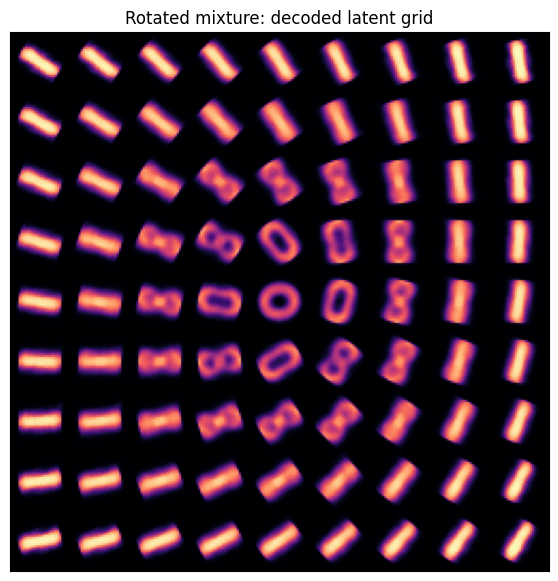

Saved /content/Fig06_mixture_decoded.png


In [10]:
D=load_digits(); raw=(D.images/16.).astype('float32'); labs=D.target

def rotate_digit(img,angle):
    # Upsample 8x8 digits to 20x20, center in a 28x28 canvas, rotate without wrapping.
    enlarged=zoom(img,2.5,order=1)
    canvas=np.zeros((28,28),dtype='float32')
    canvas[4:24,4:24]=enlarged
    return np.clip(rotate(canvas,angle,reshape=False,order=1,mode='constant',cval=0),0,1)

def rotated_set(classes,seed=17):
    rng=np.random.default_rng(seed)
    choose=np.where(np.isin(labs,classes))[0]
    if FAST_MODE: choose=rng.choice(choose,size=min(len(choose),200),replace=False)
    nrot=4 if FAST_MODE else (8 if len(classes)>1 else 16)
    images=[]; labels=[]; angles=[]
    for idx in choose:
        for theta in rng.uniform(0,360,nrot):
            images.append(rotate_digit(raw[idx],theta).ravel())
            labels.append(labs[idx]);angles.append(theta)
    return np.array(images,dtype='float32'),np.array(labels),np.array(angles),choose

for classes,tag in [([1],'digit1'),([0],'digit0'),([8],'digit8'),([0,1,3,8],'mixture')]:
    x,y,angle,base_ids=rotated_set(classes)
    model=fit_vae(x,beta=1.,epochs=5 if FAST_MODE else 80,hidden=256)
    z=encode_all(model,x)
    fig,ax=plt.subplots(figsize=(5.3,5.0))
    if len(classes)==1:
        sc=ax.scatter(z[:,0],z[:,1],c=np.mod(angle,180),cmap='twilight',s=4,alpha=.7)
        fig.colorbar(sc,ax=ax,label='Angle modulo 180°')
    else:
        for k in classes:ax.scatter(z[y==k,0],z[y==k,1],s=3,alpha=.55,label=str(k))
        ax.legend(title='Digit')
    ax.set(xlabel='$z_1$',ylabel='$z_2$',title=f'Rotated {tag}: encoded means')
    save_panel(fig,f'Fig06_{tag}_encoded.png')
    lo=np.percentile(z,1,axis=0);hi=np.percentile(z,99,axis=0)
    zgrid=np.stack(np.meshgrid(np.linspace(lo[0],hi[0],9),np.linspace(lo[1],hi[1],9)),axis=-1).reshape(-1,2)
    imgs=decode_all(model,zgrid).reshape(81,28,28)
    atlas=np.concatenate([np.concatenate(imgs[i*9:(i+1)*9],axis=1) for i in range(9)],axis=0)
    fig,ax=plt.subplots(figsize=(7,7));ax.imshow(atlas,cmap='magma',vmin=0,vmax=1)
    ax.set(title=f'Rotated {tag}: decoded latent grid',xticks=[],yticks=[])
    save_panel(fig,f'Fig06_{tag}_decoded.png')

    # Orientation sweep of a single base image. Training identities are reused.
    if len(classes)==1:
        base=raw[base_ids[0]]
        angles=np.linspace(0,360,73)
        trace=encode_all(model,np.stack([rotate_digit(base,t).ravel() for t in angles]).astype('float32'))
        center=np.mean(trace,axis=0)
        phase=np.unwrap(np.arctan2(trace[:,1]-center[1],trace[:,0]-center[0]))
        winding=(phase[-1]-phase[0])/(2*np.pi)
        fig,ax=plt.subplots(figsize=(5.3,4.4))
        ax.plot(angles,phase)
        ax.set(xlabel='Input rotation angle (degrees)',ylabel='Unwrapped latent angle',
               title=f'{tag}: observed winding ≈ {winding:.2f}')
        save_panel(fig,f'Fig06_{tag}_winding.png')
